# M07 — Binary Models and Evaluation

M06 ka Normal/High data use karke Bus aur Rail models train aur compare karte hain. Ye historical simulation hai.

## 1. Libraries and paths

In [1]:
import os
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, balanced_accuracy_score, f1_score
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

processed = r"C:\UZZAM WORK\5th Semester\Artificial Intelligence & Expert Systems\Project\Transit_Ridership_M01_Setup\Transit_Ridership_M10_Reviewed\transit-ridership\backend\data\processed"
raw = r"C:\UZZAM WORK\5th Semester\Artificial Intelligence & Expert Systems\Project\Transit_Ridership_M01_Setup\Transit_Ridership_M10_Reviewed\transit-ridership\backend\data\raw"
model_folder = r"C:\UZZAM WORK\5th Semester\Artificial Intelligence & Expert Systems\Project\Transit_Ridership_M01_Setup\Transit_Ridership_M10_Reviewed\transit-ridership\backend\models"
print("Python:", sys.executable)

Python: c:\Users\muham\cta-m03-venv\Scripts\python.exe


## 2. M06 data aur 2026 history

In [2]:
def load_data(mode):
    id_column = "route" if mode == "bus" else "station_id"

    old = pd.read_csv(
        processed + f"\\{mode}_binary_model_data.csv",
        dtype={"entity_id": str}, parse_dates=["date"]
    )
    if not old["target"].isin(["Normal", "High"]).all():
        raise ValueError(f"{mode}: M06 target Normal/High hona chahiye")
    old = old.rename(columns={"lag_91_rides": "lag91", "day_of_month": "dom"})
    old["target"] = old["target"].map({"Normal": 0, "High": 1})
    old = old[["entity_id", "date", "weekday", "month", "dom", "lag91", "target"]]

    history = pd.read_csv(
        processed + f"\\{mode}_cleaned.csv",
        dtype={id_column: str}, parse_dates=["date"]
    ).rename(columns={id_column: "entity_id"})
    history = history[["entity_id", "date", "rides"]]

    recent = pd.read_csv(
        raw + f"\\{mode}_original.csv",
        usecols=[id_column, "date", "rides"], dtype=str
    ).rename(columns={id_column: "entity_id"})
    recent["date"] = pd.to_datetime(recent["date"].str.strip(), format="mixed")
    recent = recent[recent["date"].between("2026-01-01", "2026-08-31 23:59:59")].copy()
    recent["entity_id"] = recent["entity_id"].str.strip()
    recent["date"] = recent["date"].dt.normalize()
    valid_rides = recent["rides"].str.fullmatch(r"(?:\d+|\d{1,3}(?:,\d{3})+)", na=False)
    if not valid_rides.all() or recent["entity_id"].eq("").any():
        raise ValueError(f"{mode}: invalid 2026 ridership or ID")
    recent["rides"] = pd.to_numeric(recent["rides"].str.replace(",", "", regex=False))
    total_2026 = len(recent)

    history = pd.concat([history, recent[["entity_id", "date", "rides"]]], ignore_index=True)
    history = history.sort_values(["entity_id", "date"]).reset_index(drop=True)
    if history.duplicated(["entity_id", "date"]).any():
        raise ValueError(f"{mode}: duplicate ID/date in history")

    limits = pd.read_csv(
        processed + f"\\{mode}_train_thresholds.csv",
        dtype={"entity_id": str}, float_precision="round_trip"
    )
    if limits["entity_id"].duplicated().any() or (limits["lower"] >= limits["upper"]).any():
        raise ValueError(f"{mode}: invalid M06 thresholds")
    past = history.copy()
    past["date"] = past["date"] + pd.Timedelta(days=91)
    past = past.rename(columns={"rides": "lag91"})
    recent = recent.merge(past, on=["entity_id", "date"], how="left", validate="one_to_one")
    recent = recent.merge(limits[["entity_id", "lower", "upper"]], on="entity_id", how="left")
    recent = recent[recent["upper"].notna() & recent["lag91"].notna()].copy()
    recent["target"] = (recent["rides"] > recent["upper"]).astype(int)
    recent["weekday"] = recent["date"].dt.dayofweek
    recent["month"] = recent["date"].dt.month
    recent["dom"] = recent["date"].dt.day
    recent = recent[["entity_id", "date", "weekday", "month", "dom", "lag91", "target"]]

    data = pd.concat([old, recent], ignore_index=True)
    data = data.sort_values(["entity_id", "date"]).reset_index(drop=True)
    data = data.merge(limits[["entity_id", "lower", "upper"]], on="entity_id", how="left")
    if data[["lower", "upper", "lag91", "target"]].isna().any().any():
        raise ValueError(f"{mode}: missing target, threshold or 91-day history")
    if data.duplicated(["entity_id", "date"]).any():
        raise ValueError(f"{mode}: duplicate ID/date in M06 data")
    print(f"{mode}: {len(old):,} M06 rows; 2026 = {len(recent):,} / {total_2026:,}")
    return data, history, limits

data = {}
histories = {}
thresholds = {}
for mode in ["bus", "rail"]:
    data[mode], histories[mode], thresholds[mode] = load_data(mode)

C:\Users\muham\AppData\Local\Temp\ipykernel_20652\3661534314.py:46: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  past["date"] = past["date"] + pd.Timedelta(days=91)


bus: 154,618 M06 rows; 2026 = 27,309 / 27,949


C:\Users\muham\AppData\Local\Temp\ipykernel_20652\3661534314.py:46: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  past["date"] = past["date"] + pd.Timedelta(days=91)


rail: 193,170 M06 rows; 2026 = 34,263 / 34,992


## 3. Extra historical features

Features prediction date se kam az kam 91 din purani hain. Publication delay verify nahi hui.

In [4]:
features = [
    "entity_code", "weekday", "month", "dom", "lower", "upper",
    "lag91", "lag98", "lag105", "lag112", "lag119", "lag364",
    "avg7", "avg28", "avg56", "rel_lag91", "rel_lag98", "rel_lag105",
    "rel_lag112", "rel_lag119", "rel_lag364", "rel_avg7", "rel_avg28", "rel_avg56"
]

entity_maps = {}
for mode in ["bus", "rail"]:
    df = data[mode]
    history = histories[mode]

    for days in [98, 105, 112, 119, 364]:
        past = history.copy()
        past["date"] = past["date"] + pd.Timedelta(days=days)
        past = past.rename(columns={"rides": f"lag{days}"})
        df = df.merge(past, on=["entity_id", "date"], how="left", validate="one_to_one")

    for days in [7, 28, 56]:
        past = history.groupby("entity_id").rolling(f"{days}D", on="date", min_periods=1)["rides"].mean().reset_index()
        past["date"] = past["date"] + pd.Timedelta(days=91)
        past = past.rename(columns={"rides": f"avg{days}"})
        df = df.merge(past, on=["entity_id", "date"], how="left", validate="one_to_one")

    for column in ["lag91", "lag98", "lag105", "lag112", "lag119", "lag364", "avg7", "avg28", "avg56"]:
        df[f"rel_{column}"] = (df[column] - df["lower"]) / (df["upper"] - df["lower"])

    entity_maps[mode] = {entity: code for code, entity in enumerate(sorted(thresholds[mode]["entity_id"].unique()))}
    df["entity_code"] = df["entity_id"].map(entity_maps[mode]).astype("int16")
    data[mode] = df

C:\Users\muham\AppData\Local\Temp\ipykernel_2864\797062879.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  past["date"] = past["date"] + pd.Timedelta(days=days)
C:\Users\muham\AppData\Local\Temp\ipykernel_2864\797062879.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  past["date"] = past["date"] + pd.Timedelta(days=days)
C:\Users\muham\AppData\Local\Temp\ipykernel_2864\797062879.py:15: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  past["date"] = past["date"] + pd.Timedelta(day

## 4. Models aur historical baselines

Har year se pehle wali available history par model dobara train hota hai. 2024, 2025 aur 2026 pehle explore ho chuke hain.

In [5]:
def selected_model(mode):
    if mode == "bus":
        return XGBClassifier(
            n_estimators=350, learning_rate=0.04, max_depth=4,
            min_child_weight=20, reg_lambda=5, subsample=0.85,
            colsample_bytree=0.9, n_jobs=4, random_state=42, tree_method="hist"
        )
    return LGBMClassifier(
        n_estimators=350, learning_rate=0.04, num_leaves=15,
        min_child_samples=70, reg_lambda=5, n_jobs=4,
        random_state=42, verbosity=-1
    )

def scores(actual, predicted):
    return {
        "Accuracy": accuracy_score(actual, predicted),
        "Balanced accuracy": balanced_accuracy_score(actual, predicted),
        "Macro F1": f1_score(actual, predicted, average="macro", zero_division=0),
        "Normal F1": f1_score(actual, predicted, pos_label=0, zero_division=0),
        "High F1": f1_score(actual, predicted, pos_label=1, zero_division=0)
    }

results = []
models = {}
last_test = {}
for mode in ["bus", "rail"]:
    for year in [2024, 2025, 2026]:
        cutoff = pd.Timestamp(f"{year}-01-01") - pd.Timedelta(days=91)
        train = data[mode][(data[mode]["date"] >= "2022-04-02") & (data[mode]["date"] <= cutoff)]
        test = data[mode][data[mode]["date"].dt.year == year]

        model = selected_model(mode)
        model.fit(train[features], train["target"])
        tree = DecisionTreeClassifier(max_depth=8, min_samples_leaf=50, random_state=42)
        tree.fit(train[features], train["target"])

        predicted = {
            "XGBoost" if mode == "bus" else "LightGBM": model.predict(test[features]).astype(int),
            "Decision Tree": tree.predict(test[features]).astype(int),
            "91-day baseline": (test["lag91"] > test["upper"]).astype(int),
            "364-day baseline": np.where(test["lag364"].notna(),
                                         (test["lag364"] > test["upper"]).astype(int),
                                         (test["lag91"] > test["upper"]).astype(int))
        }
        for name, prediction in predicted.items():
            results.append({"Dataset": mode.title(), "Year": year, "Method": name,
                            "Rows": len(test), **scores(test["target"], prediction)})

        print(f"{mode} {year}: train={len(train):,}, test={len(test):,}, cutoff={cutoff.date()}")
        print("Training classes:", train["target"].map({0: "Normal", 1: "High"}).value_counts().to_dict())
        if year == 2026:
            models[mode] = model
            last_test[mode] = {"actual": test["target"], "predicted": predicted, "cutoff": cutoff}

results_table = pd.DataFrame(results)

C:\Users\muham\AppData\Local\Temp\ipykernel_2864\2735804838.py:28: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  cutoff = pd.Timestamp(f"{year}-01-01") - pd.Timedelta(days=91)


bus 2024: train=62,041, test=41,294, cutoff=2023-10-02
Training classes: {'Normal': 38818, 'High': 23223}


C:\Users\muham\AppData\Local\Temp\ipykernel_2864\2735804838.py:28: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  cutoff = pd.Timestamp(f"{year}-01-01") - pd.Timedelta(days=91)


bus 2025: train=103,351, test=41,174, cutoff=2024-10-02
Training classes: {'Normal': 55015, 'High': 48336}


C:\Users\muham\AppData\Local\Temp\ipykernel_2864\2735804838.py:28: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  cutoff = pd.Timestamp(f"{year}-01-01") - pd.Timedelta(days=91)


bus 2026: train=144,570, test=27,309, cutoff=2025-10-02
Training classes: {'High': 76168, 'Normal': 68402}


... (2 outputs left out)

C:\Users\muham\AppData\Local\Temp\ipykernel_2864\2735804838.py:28: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  cutoff = pd.Timestamp(f"{year}-01-01") - pd.Timedelta(days=91)


rail 2025: train=129,015, test=51,465, cutoff=2024-10-02
Training classes: {'Normal': 71154, 'High': 57861}


C:\Users\muham\AppData\Local\Temp\ipykernel_2864\2735804838.py:28: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  cutoff = pd.Timestamp(f"{year}-01-01") - pd.Timedelta(days=91)


rail 2026: train=180,480, test=34,263, cutoff=2025-10-02
Training classes: {'Normal': 91091, 'High': 89389}


## 5. Model comparison

In [6]:
results_table.round(4)

,Dataset,Year,Method,Rows,Accuracy,Balanced accuracy,Macro F1,Normal F1,High F1
0,Bus,2024,XGBoost,41294,0.8209,0.8103,0.8107,0.7666,0.8547
1,Bus,2024,Decision Tree,41294,0.7930,0.7687,0.7750,0.7114,0.8386
2,Bus,2024,91-day baseline,41294,0.7404,0.7278,0.7269,0.6662,0.7876
3,Bus,2024,364-day baseline,41294,0.7487,0.7663,0.7461,0.7207,0.7716
4,Bus,2025,XGBoost,41174,0.8714,0.8360,0.8467,0.7851,0.9082
5,Bus,2025,Decision Tree,41174,0.8593,0.8206,0.8317,0.7635,0.8998
6,Bus,2025,91-day baseline,41174,0.7803,0.7496,0.7482,0.6581,0.8382
7,Bus,2025,364-day baseline,41174,0.8320,0.8328,0.8153,0.7596,0.8709
8,Bus,2026,XGBoost,27309,0.8843,0.8349,0.8552,0.7902,0.9201
9,Bus,2026,Decision Tree,27309,0.8650,0.8147,0.8321,0.7577,0.9064


## 6. 2026 classification reports aur confusion matrices


BUS — XGBoost
              precision    recall  f1-score   support

      Normal       0.90      0.71      0.79      8438
        High       0.88      0.96      0.92     18871

    accuracy                           0.88     27309
   macro avg       0.89      0.83      0.86     27309
weighted avg       0.89      0.88      0.88     27309


BUS — Decision Tree
              precision    recall  f1-score   support

      Normal       0.85      0.68      0.76      8438
        High       0.87      0.95      0.91     18871

    accuracy                           0.86     27309
   macro avg       0.86      0.81      0.83     27309
weighted avg       0.86      0.86      0.86     27309



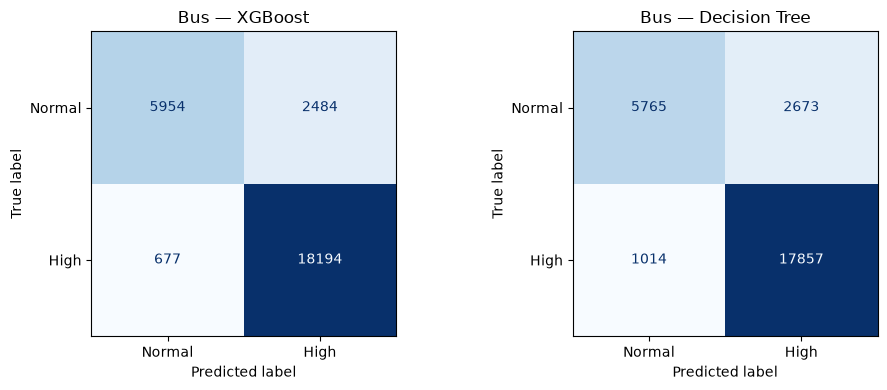


RAIL — LightGBM
              precision    recall  f1-score   support

      Normal       0.88      0.80      0.84     12104
        High       0.89      0.94      0.92     22159

    accuracy                           0.89     34263
   macro avg       0.89      0.87      0.88     34263
weighted avg       0.89      0.89      0.89     34263


RAIL — Decision Tree
              precision    recall  f1-score   support

      Normal       0.87      0.76      0.81     12104
        High       0.88      0.94      0.91     22159

    accuracy                           0.87     34263
   macro avg       0.87      0.85      0.86     34263
weighted avg       0.87      0.87      0.87     34263



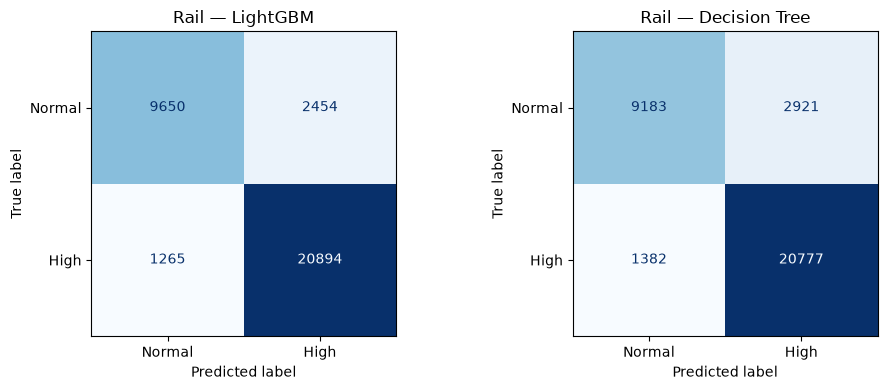

In [7]:
for mode in ["bus", "rail"]:
    actual = last_test[mode]["actual"]
    predictions = last_test[mode]["predicted"]
    methods = ["XGBoost" if mode == "bus" else "LightGBM", "Decision Tree"]
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    for ax, method in zip(axes, methods):
        print(f"\n{mode.upper()} — {method}")
        print(classification_report(actual, predictions[method], labels=[0, 1],
                                    target_names=["Normal", "High"], zero_division=0))
        ConfusionMatrixDisplay.from_predictions(
            actual, predictions[method], labels=[0, 1], display_labels=["Normal", "High"],
            ax=ax, cmap="Blues", colorbar=False
        )
        ax.set_title(f"{mode.title()} — {method}")
    plt.tight_layout()
    plt.show()

## 7. Save selected models

Saved models 2026 historical evaluation ke liye hain. Dobara run karne par existing model files overwrite hongi.

In [8]:
os.makedirs(model_folder, exist_ok=True)

for mode in ["bus", "rail"]:
    bundle = {
        "model": models[mode],
        "features": features,
        "entity_codes": entity_maps[mode],
        "thresholds": thresholds[mode],
        "training_cutoff": str(last_test[mode]["cutoff"].date()),
        "classes": {0: "Normal", 1: "High"}
    }
    output = model_folder + f"\\{mode}_binary_model.joblib"
    joblib.dump(bundle, output)
    print(f"Saved: {output} | training cutoff: {bundle['training_cutoff']}")

Saved: C:\UZZAM WORK\5th Semester\Artificial Intelligence & Expert Systems\Project\Transit_Ridership_M01_Setup\Transit_Ridership_M10_Reviewed\transit-ridership\backend\models\bus_binary_model.joblib | training cutoff: 2025-10-02
Saved: C:\UZZAM WORK\5th Semester\Artificial Intelligence & Expert Systems\Project\Transit_Ridership_M01_Setup\Transit_Ridership_M10_Reviewed\transit-ridership\backend\models\rail_binary_model.joblib | training cutoff: 2025-10-02


2026 January–August ka historical comparison hai. High relative ridership hai; isay overcrowding ya live prediction na samjho.